# 4 — The revised Most Improved race

**In brief**
- **Question:** How good is the Most Improved model now, at each point of a season, how did it get here, and can its chances be trusted?
- **Answer:** Before the season the model finds players set up to improve, not the winner (top 7 in 5 of 9 strict seasons at preseason). It sharpens through the season: at day 30 the winner is in the top 7 in 12 of 21 strict seasons, and **by the All-Star break the race is essentially decided** (19 of 21, median rank 3), as well as at season's end. It roughly doubled in sharpness over nine tested decisions, the biggest gain coming from understanding what voters reward. Its chances are honest except for big early favourites, which are flagged rather than corrected.
- **Decisions** ([decision log](../docs/DECISIONS.md)): [D22](../docs/DECISIONS.md), [D24](../docs/DECISIONS.md), [D26](../docs/DECISIONS.md)–[D30](../docs/DECISIONS.md), [D32](../docs/DECISIONS.md), [D38](../docs/DECISIONS.md)–[D42](../docs/DECISIONS.md), [D44](../docs/DECISIONS.md), [D45](../docs/DECISIONS.md), [D48](../docs/DECISIONS.md) (the checkpoints).
- **Where it fits:** The current model, built on the basic race (segment 1) and the investigations (segment 3). The daily board is in [4b, the live race](4b_live_race.ipynb).
- **Dated:** written 13 November 2026 from notebooks 11, 15, 19, 20, 21B and 22 (now in [archive/](archive)). About 10–15 minutes to run.

**Six checkpoints** ([D48](../docs/DECISIONS.md)): after the previous season, preseason, **day 15** and **day 30** after opening night, the **All-Star break**, and the end of the season. Two models:
- **Before the season** (after the previous season; preseason): last season's role and production, age and experience, last season's trend, how established the player is, an open role (a 20-point scorer left), and, at preseason, form per 36 minutes in preseason games ([D26](../docs/DECISIONS.md)–[D29](../docs/DECISIONS.md)). 2012-13 → 2025-26, because preseason game logs start then.
- **In season** (the live race): the change on the baseline season in every box-score statistic, absolute and relative; the team's change in winning; age and second year; the baseline level with a turning point; already an All-Star, back from a lost season, already clearly a star ([D38](../docs/DECISIONS.md)–[D42](../docs/DECISIONS.md)). 2000-01 → 2025-26.

**Two tests:** *strict* predicts each season from earlier seasons only (the one to trust); *leave-one-out* from all other seasons. **× a blind guess:** how much more chance the model gave the real winner than an even split. **Honest caveat:** each season is predicted from earlier seasons, but the model's settings (λ = 3, the elite threshold) and its later inputs were chosen by looking at these same seasons, so even the strict scores flatter it somewhat. The first clean test is 2026-27, with the model frozen ([D44](../docs/DECISIONS.md)).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from unicorn import mip_history as MH
from unicorn.allstars import add_prior_allstar, load_selections
from unicorn.gamelogs import GAMELOG_SEASONS, build_game_table, load_game_logs
from unicorn.hot_start import add_stale
from unicorn.labels import MIP_WINNERS
from unicorn.mip import AGE, GAMELOG_DEFENSE, GAMELOG_DELTAS, RELATIVE, SECOND_YEAR, TEAM, ChoiceModel
from unicorn.mip_eval import LIVE_INPUTS, LIVE_LEVEL, LIVE_TURN, LIVE_TURN_CHOICES, current_frame, scorecard, turning_point_ranks, winner_ranks
from unicorn.plotting import BLUE, FIG_DIR, INK, INK2, MUTED, ORANGE, SERIES, SURFACE, apply_style
from unicorn.preseason import (ESTABLISHED, LAST_SEASON_LEAN, MOMENTUM, PRE_FORM_LEAN, PROFILE, RETURNING, TEAM_CHANGE, TURN, USED,
                               add_pool_flags, add_star_left, add_turning_point, load_preseason, preseason_frame)
from unicorn.raw import PROJECT_ROOT

warnings.filterwarnings("ignore")
apply_style()
pd.set_option("display.max_colwidth", None)
DATA = PROJECT_ROOT / "data" / "processed"
L2 = MH.L2
sel = load_selections()
g = MH.load_games(); info = MH.player_info(); votes, winners = MH.voting(g)       # 1999-00 → 2025-26; baseline = last season with 33%+ of games (D22)

def at(games, point, **kw):
    """Every past season's candidates at a checkpoint: a day after opening night, 'break' (games before the All-Star break) or None (season's end)."""
    if point == "break":
        return current_frame(games[~games["after_all_star"]], info, winners, sel, day=None, **kw)
    return current_frame(games, info, winners, sel, day=point, **kw)

regular = pd.read_parquet(DATA / "player_games.parquet"); ps = pd.read_parquet(DATA / "player_season.parquet")
pre = load_preseason(regular=regular, refresh_latest=False)
F = add_stale(add_prior_allstar(add_star_left(add_turning_point(add_pool_flags(preseason_frame(pre, regular, ps), MIP_WINNERS)), pre, regular), sel))
FH, FT = F[F["season"] != "2026-27"].reset_index(drop=True), F[F["season"] == "2026-27"].reset_index(drop=True)
AFTER_LAST = LAST_SEASON_LEAN + PROFILE + MOMENTUM + TURN + ESTABLISHED + RETURNING      # the preseason model without preseason games
print(f"in season: {g['season'].nunique()} seasons of games; before the season: {FH['season'].nunique()} preseasons, {len(FH):,} candidates")

in season: 27 seasons of games; before the season: 14 preseasons, 5,230 candidates


## 4A — Six checkpoints: how good is the model at each point of the season?

The current model at each checkpoint, with both tests. In season, the turning point is chosen inside each training window, exactly as the live race chooses it each day ([D32](../docs/DECISIONS.md)). Before the season it is fixed at 20 points, as the preseason model uses it ([D27](../docs/DECISIONS.md)).

In [2]:
CHECKPOINTS = {"after the previous season": ("before", AFTER_LAST), "preseason": ("before", USED),
               "day 15": ("in", 15), "day 30": ("in", 30), "All-Star break": ("in", "break"), "end of season": ("in", None)}
NO_TURN = [c for c in LIVE_INPUTS if c != "over_turn"]
frames, results = {}, {}
for name, (kind, arg) in CHECKPOINTS.items():
    for scheme in ["strict", "leave-one-out"]:
        if kind == "before":
            r = winner_ranks(FH, arg, L2, scheme)
        else:
            frames.setdefault(name, at(g, arg))
            r = turning_point_ranks(frames[name], NO_TURN, LIVE_LEVEL, LIVE_TURN_CHOICES, scheme=scheme)
        results[(name, scheme)] = r
board = pd.DataFrame({k: scorecard(r) for k, r in results.items()}).T
board.index.names = ["checkpoint", "test"]
board[["seasons", "winner #1", "in top 3", "in top 7", "median rank", "× a blind guess"]].style.format(
    {"seasons": "{:.0f}", "winner #1": "{:.0f}", "in top 3": "{:.0f}", "in top 7": "{:.0f}", "median rank": "{:.0f}", "× a blind guess": "{:.1f}"})

,2012-13,2013-14,2014-15,2015-16,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25,2025-26
after the previous season,22,57,8,100,2,24,75,1,73,32,14,3,34,40
preseason,6,43,4,6,4,6,3,1,160,11,3,17,4,24
day 15,27,168,5,1,1,4,30,2,3,3,4,2,28,28
day 30,26,39,1,1,1,3,6,3,6,1,4,2,11,9
All-Star break,4,7,1,1,1,1,1,5,3,1,1,5,6,5
end of season,4,13,1,1,1,1,1,7,4,1,1,5,1,2


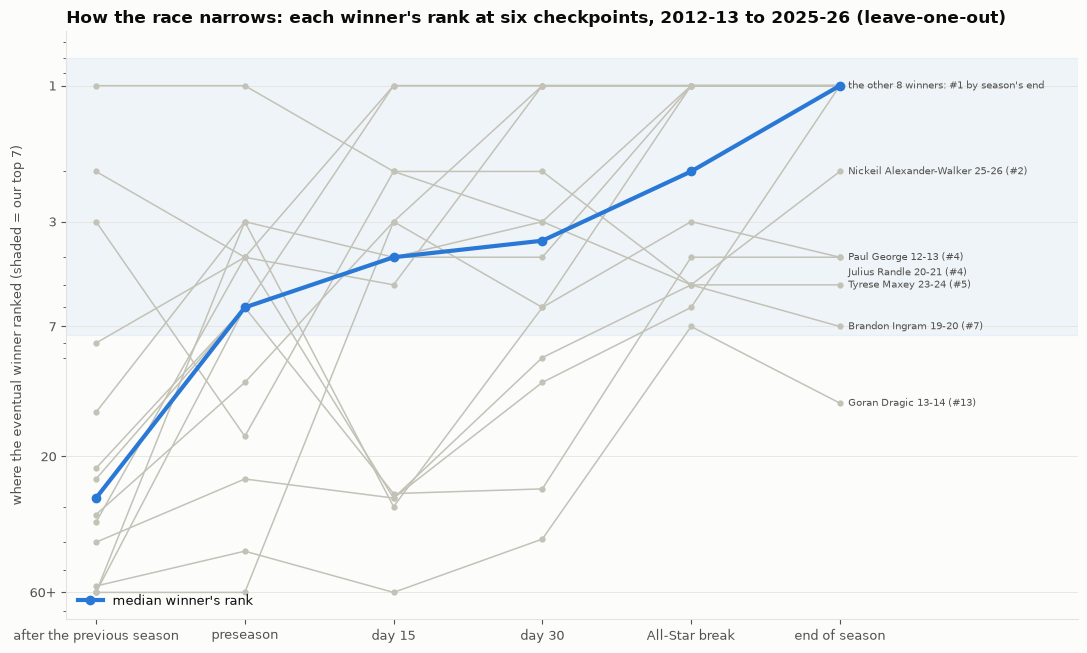

In [3]:
# each winner's rank at every checkpoint (leave-one-out, so every season from 2012-13 has all six)
ranks = pd.DataFrame({name: results[(name, "leave-one-out")]["rank"].astype(float) for name in CHECKPOINTS}).sort_index().loc["2012-13":]   # missing = not yet a candidate
names = {s: g.loc[(g["player_id"] == pid), "player_name"].iloc[-1] for s, pid in winners.items() if s in ranks.index}
fig, ax = plt.subplots(figsize=(11, 6.6))
x = np.arange(len(CHECKPOINTS))
used = {}
for s, r in ranks.iterrows():
    ax.plot(x, r.clip(upper=60), color=MUTED, linewidth=1.1, marker="o", markersize=3.5, zorder=2)
    end = r.iloc[-1]
    if end > 1:                                            # label the winners the model did not have at #1 by season's end
        k = used.get(end, 0); used[end] = k + 1             # tied ranks: stack the labels
        ax.annotate(f"{names[s]} {s[2:]} (#{int(end)})", (x[-1], min(end, 60)), xytext=(6, -11 * k), textcoords="offset points", va="center", fontsize=7.5, color=INK2)
n1 = int((ranks.iloc[:, -1] == 1).sum())
ax.annotate(f"the other {n1} winners: #1 by season's end", (x[-1], 1), xytext=(6, 0), textcoords="offset points", va="center", fontsize=7.5, color=INK2)
ax.plot(x, ranks.median(), color=BLUE, linewidth=3, marker="o", zorder=3, label="median winner's rank")
ax.set_yscale("log"); ax.invert_yaxis(); ax.set_yticks([1, 3, 7, 20, 60], ["1", "3", "7", "20", "60+"])
ax.axhspan(0.8, 7.5, color=BLUE, alpha=0.06, zorder=0)
ax.set_xticks(x, list(CHECKPOINTS), fontsize=9.5); ax.set_xlim(-0.2, len(x) + 0.6); ax.grid(axis="x", visible=False)
ax.set_ylabel("where the eventual winner ranked (shaded = our top 7)"); ax.legend(frameon=False, loc="lower left")
ax.set_title("How the race narrows: each winner's rank at six checkpoints, 2012-13 to 2025-26 (leave-one-out)", loc="left", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "4_checkpoints.png", dpi=150, bbox_inches="tight")
ranks.T.astype("Int64")

## 4B — How the model got here, one decision at a time

The model was not designed in one step. Each stage below adds one decision, made because something was wrong or missing, and every stage is scored on the same test bed. The settings are held fixed (λ = 3; turning point at 20 points for stages 4–6 and at game score 14 for stages 7–8) so that only the inputs change.

In [4]:
games0, _, _ = build_game_table(load_game_logs(MH.OLD_SEASONS + GAMELOG_SEASONS), baseline_min_share=0.0)   # the first baseline: simply last season (before D22)
games0["day"] = (games0["game_date"] - games0.groupby("season")["game_date"].transform("min")).dt.days
POINTS = {"day 15": 15, "day 30": 30, "All-Star break": "break", "end of season": None}
DX = GAMELOG_DELTAS + GAMELOG_DEFENSE
BASE = DX + RELATIVE + TEAM + AGE + SECOND_YEAR
STAGES = [("0. Biggest points jump", "–", "last season", "ppg_delta"),
          ("1. Choice model on box-score changes", "D24", "last season", DX),
          ("2. Skip injury-shortened baselines", "D22", "33%+", DX),
          ("3. + relative change, team, age, second year", "D24", "33%+", BASE),
          ("4. + turning point at 20 points", "D27", "33%+", BASE + ["base_ppg", "over_turn"]),
          ("5. + already an All-Star", "D38", "33%+", BASE + ["base_ppg", "over_turn", "prior_allstar"]),
          ("6. + back from a lost season", "D39", "33%+", BASE + ["base_ppg", "over_turn", "prior_allstar", "stale"]),
          ("7. Turning point on game score", "D41", "33%+, game score", BASE + ["base_game_score", "over_turn", "prior_allstar", "stale"]),
          ("8. + already clearly a star", "D42", "33%+, game score", BASE + ["base_game_score", "over_turn", "prior_allstar", "stale", "elite_level", "base_star_tier"])]
sframes = {}
for p, arg in POINTS.items():
    sframes[(p, "last season")] = at(games0, arg, level_col="base_ppg", turn=20)
    sframes[(p, "33%+")] = at(g, arg, level_col="base_ppg", turn=20)
    sframes[(p, "33%+, game score")] = at(g, arg, level_col=LIVE_LEVEL, turn=LIVE_TURN)
rows = []
for stage, dec, base, feats in STAGES:
    for p in POINTS:
        f = sframes[(p, base)]
        for scheme in ["strict", "leave-one-out"]:
            r = winner_ranks(f, rule=feats, scheme=scheme) if isinstance(feats, str) else winner_ranks(f, feats, L2, scheme)
            rows.append({"stage": stage, "decision": dec, "point": p, "test": scheme, **scorecard(r)})
stages = pd.DataFrame(rows)
stages[stages["test"] == "strict"].pivot_table(index=["stage", "decision"], columns="point", values="× a blind guess", sort=False)[list(POINTS)].round(1)

,point,day 15,day 30,All-Star break,end of season
stage,decision,,,,
1. Choice model on box-score changes,D24,3.0,4.6,12.0,11.4
2. Skip injury-shortened baselines,D22,3.3,5.5,14.2,13.7
"3. + relative change, team, age, second year",D24,4.3,7.0,19.1,19.2
4. + turning point at 20 points,D27,5.1,8.4,22.0,23.0
5. + already an All-Star,D38,5.4,9.0,23.5,24.6
6. + back from a lost season,D39,5.6,9.2,23.6,24.9
7. Turning point on game score,D41,5.6,9.3,23.8,24.9
8. + already clearly a star,D42,5.8,9.6,25.0,26.1


In [5]:
PRE_STAGES = [("0. Last season's minutes and points", "–", ["mpg_last", "ppg_last"]), ("1. + age, second year, team", "D24", LAST_SEASON_LEAN + PROFILE),
              ("2. + last season's trend", "–", LAST_SEASON_LEAN + PROFILE + MOMENTUM), ("3. + preseason form per 36", "D26", LAST_SEASON_LEAN + PROFILE + MOMENTUM + PRE_FORM_LEAN),
              ("4. + turning point at 20 points", "D27", LAST_SEASON_LEAN + PROFILE + MOMENTUM + PRE_FORM_LEAN + TURN),
              ("5. + a 20-point scorer left", "D29", LAST_SEASON_LEAN + PROFILE + MOMENTUM + PRE_FORM_LEAN + TURN + TEAM_CHANGE),
              ("6. + already an All-Star", "D38", LAST_SEASON_LEAN + PROFILE + MOMENTUM + PRE_FORM_LEAN + TURN + TEAM_CHANGE + ESTABLISHED),
              ("7. + back from a lost season", "D39", USED)]
pre_stages = pd.DataFrame([{"stage": s, "decision": d, "test": t, **scorecard(winner_ranks(FH, f, L2, "strict" if t == "strict" else "loso"))}
                           for s, d, f in PRE_STAGES for t in ["strict", "leave-one-out"]])
pre_stages.pivot_table(index=["stage", "decision"], columns="test", values=["× a blind guess", "in top 7", "median rank"], sort=False).round(1)

× a blind guess                \
test                                                  strict leave-one-out   
stage                               decision                                 
0. Last season's minutes and points –                    1.4           1.4   
1. + age, second year, team         D24                  1.7           1.8   
2. + last season's trend            –                    1.8           2.6   
3. + preseason form per 36          D26                  2.9           5.1   
4. + turning point at 20 points     D27                  3.3           5.6   
5. + a 20-point scorer left         D29                  4.9           7.1   
6. + already an All-Star            D38                  5.6           8.2   
7. + back from a lost season        D39                  6.0           8.9   

                                             in top 7                \
test                                           strict leave-one-out   
stage                               decision                          
0. Last season's minutes and points –             0.0           1.0   
1. + age, second year, team         D24           0.0           3.0   
2. + last season's trend            –             2.0           3.0   
3. + preseason form per 36          D26           2.0           4.0   
4. + turning point at 20 points     D27           1.0           3.0   
5. + a 20-point scorer left         D29           4.0           7.0   
6. + already an All-Star            D38           5.0           8.0   
7. + back from a lost season        D39           5.0           9.0   

                                             median rank                
test                                              strict leave-one-out  
stage                               decision                            
0. Last season's minutes and points –               50.0          51.0  
1. + age, second year, team         D24             79.0          44.0  
2. + last season's trend            –               44.0          39.5  
3. + preseason form per 36          D26             16.0          14.5  
4. + turning point at 20 points     D27             14.0          11.5  
5. + a 20-point scorer left         D29             15.0           7.0  
6. + already an All-Star            D38              7.0           6.0  
7. + back from a lost season        D39              7.0           6.0

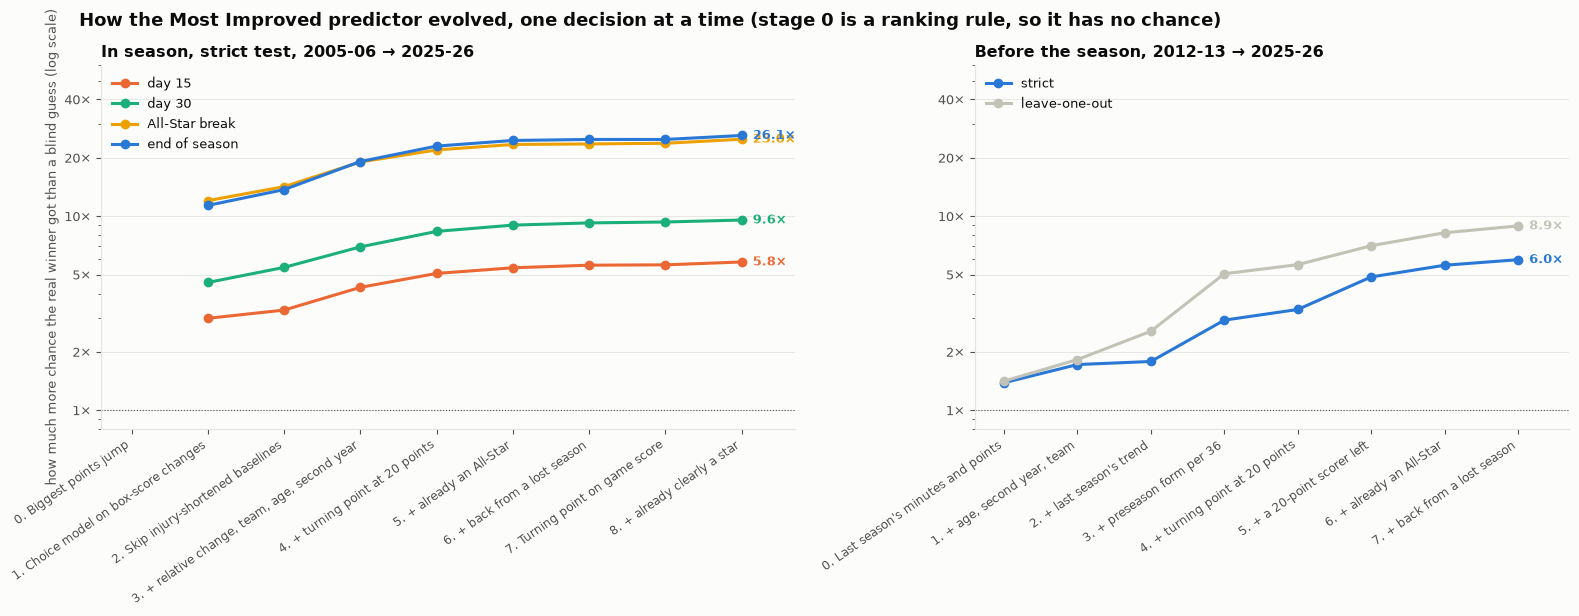

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 6.2), gridspec_kw={"width_ratios": [7, 6]})
for ax, data, names_, lines, title in [
        (a1, stages, [s[0] for s in STAGES], [(p, c) for p, c in zip(POINTS, [ORANGE, SERIES[2], SERIES[3], BLUE])], "In season, strict test, 2005-06 → 2025-26"),
        (a2, pre_stages, [s[0] for s in PRE_STAGES], [("strict", BLUE), ("leave-one-out", MUTED)], "Before the season, 2012-13 → 2025-26")]:
    x = np.arange(len(names_))
    for key, col in lines:
        d = (data[(data["test"] == "strict") & (data["point"] == key)] if "point" in data and key in POINTS else data[data["test"] == key]).set_index("stage").reindex(names_)
        y = d["× a blind guess"].to_numpy()
        ax.plot(x, y, marker="o", color=col, linewidth=2.2, label=key)
        last = np.where(~np.isnan(y))[0][-1]
        ax.annotate(f"{y[last]:.1f}×", (x[last], y[last]), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9.5, color=col, fontweight="bold")
    ax.set_yscale("log"); ax.yaxis.set_major_formatter(lambda v, _: f"{v:g}×"); ax.yaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_yticks([1, 2, 5, 10, 20, 40]); ax.set_ylim(0.8, 60); ax.axhline(1, color=INK2, linewidth=0.8, linestyle=":")
    ax.set_xticks(x, names_, rotation=35, ha="right", fontsize=8.5); ax.set_xlim(-0.4, len(x) - 0.3); ax.grid(axis="x", visible=False)
    ax.set_title(title, loc="left", fontsize=11.5); ax.legend(frameon=False, loc="upper left", fontsize=9)
a1.set_ylabel("how much more chance the real winner got than a blind guess (log scale)")
fig.suptitle("How the Most Improved predictor evolved, one decision at a time (stage 0 is a ranking rule, so it has no chance)", x=0.06, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "4_evolution.png", dpi=150, bbox_inches="tight")

## 4C — Are the chances honest?

When the race gives players 20%, do about one in five win? Every candidate's out-of-sample chance (leave-one-out, the live race's inputs, 2000-01 → 2025-26) is placed in a band, at ten points of the season, and the average chance is compared with the share who won. The 90% range for the share comes from the beta distribution.

In [7]:
from scipy.stats import beta
from unicorn.calibration import scores, softmax_T

DAYS = [2, 7, 14, 19, 30, 45, 60, 85, 120, None]
lab = lambda d: "end" if d is None else f"day {d}"
oos = {}
for day in DAYS:
    f = current_frame(g, info, winners, sel, day=day)
    for s in sorted(f["season"].unique()):
        te = f[f["season"] == s]
        if te["mip"].any():
            oos[(lab(day), s)] = (scores(ChoiceModel(LIVE_INPUTS, L2).fit(f[f["season"] != s]), te), int(np.flatnonzero(te["mip"].to_numpy())[0]))
BANDS, BAND_NAMES = [0, 0.01, 0.03, 0.10, 0.25, 1.0], ["under 1%", "1–3%", "3–10%", "10–25%", "25%+"]
def reliability(days):
    r = pd.DataFrame([(p, j == w) for (d, s), (sc, w) in oos.items() if d in days for j, p in enumerate(softmax_T(sc, 1.0))], columns=["chance", "won"])
    out = r.groupby(pd.cut(r["chance"], BANDS, labels=BAND_NAMES, include_lowest=True), observed=True).agg(players=("won", "size"), winners=("won", "sum"), average_chance=("chance", "mean"))
    out["share who won"] = out["winners"] / out["players"]
    out["90% range"] = [f"{beta.ppf(0.05, w, n - w + 1):.1%}–{beta.ppf(0.95, w + 1, n - w):.1%}" for w, n in zip(out["winners"], out["players"])]
    return out
rel = pd.concat({"early season (days 7–30)": reliability(["day 7", "day 14", "day 19", "day 30"]),
                 "later season (day 60 to the end)": reliability(["day 60", "day 85", "day 120", "end"])})
rel.style.format({"average_chance": "{:.1%}", "share who won": "{:.1%}"})

In [8]:
fav = []
for day in [7, 14, 19, 30]:
    f = current_frame(g, info, winners, sel, day=day)
    for s in sorted(f["season"].unique()):
        te = f[f["season"] == s]
        if te["mip"].any():
            p = ChoiceModel(LIVE_INPUTS, L2).fit(f[f["season"] != s]).predict_proba(te)
            fav.append(te[p >= 0.25].assign(chance=p[p >= 0.25])[["season", "player_name", "chance", "mip"]])
fav = pd.concat(fav).groupby(["season", "player_name"]).agg(average_chance=("chance", "mean"), highest=("chance", "max"), won=("mip", "max"))
p = fav["average_chance"].to_numpy()
luck = ((np.random.default_rng(1).random((20000, len(p))) < p).sum(axis=1) <= fav["won"].sum()).mean()
print(f"big early favourites (25%+ on any of days 7–30): {len(fav)}; expected wins {p.sum():.1f}; won {int(fav['won'].sum())}; "
      f"chance that luck alone gives this few: {luck:.1%}")
print("those who won:", ", ".join(f"{n} {s}" for s, n in fav[fav["won"]].index))

big early favourites (25%+ on any of days 7–30): 19; expected wins 7.5; won 3; chance that luck alone gives this few: 2.0%
those who won: Zach Randolph 2003-04, Ja Morant 2021-22, Tyrese Maxey 2023-24


**Decision ([D40](../docs/DECISIONS.md)): flag the big early favourite, do not correct it.** A correction fitted to about 19 players would be close to fitting noise. The live race prints a note whenever a chance is above 25% before day 45. A single correction for all chances (temperature scaling) was also tested and made the fit worse when learned without the season it was tested on (archived [notebook 20](archive/20_calibration.ipynb)).

## 4D — The turning point: on points or on game score?

Established players are MVP material, not Most Improved, so the baseline level counts *for* a candidate up to a turning point and *against* him above it ([D27](../docs/DECISIONS.md)). It was defined on points. Is it really scoring that voters hold against a player, or being established in general? Tested on game score and usage, each with its turning point chosen inside training, by a rule written first: replace points only if better in the strict test at most points of the season, without fewer winners in the top 7. From the archived [notebook 21B](archive/21_beyond_ppg.ipynb) (12 November; about 30 minutes to re-run):

| | Day 19 | Day 85 | Season's end |
|---|---|---|---|
| Strict, points | 6.3× | 19.4× | 23.4× |
| Strict, **game score** | **6.4×** | 19.2× (one fewer winner in the top 7) | **24.4×** |
| Leave-one-out, points | 8.1× | | 35.0× |
| Leave-one-out, game score | 8.3× | | 35.3× |

**Decision ([D41](../docs/DECISIONS.md)): game score in the live race; points kept before the season,** where nothing beat it and usage was worse. The differences are small, and that is the finding: baseline points and game score correlate at 0.955, so voters discount *established* players whichever way it is measured.

## 4E — 2026-27 at each checkpoint

The same six checkpoints for this season. The first two come from the models before the season (trained on all past preseasons), the in-season ones from the live race's board as it was saved that day ([4b](4b_live_race.ipynb)).

In [9]:
def top7(features):
    p = ChoiceModel(features, L2).fit(FH).predict_proba(FT)
    t = FT.assign(chance=p).nlargest(7, "chance")
    return [f"{n} ({c:.1%})" for n, c in zip(t["player_name"], t["chance"])]
daily = pd.read_parquet(DATA / "mip_race_daily_2026_27.parquet")
on_day = lambda d: [f"{n} ({c:.1%})" for n, c in daily[daily["day"] == d].nsmallest(7, "rank")[["player_name", "chance"]].itertuples(index=False)]
latest = int(daily["day"].max())
cols = {"after the previous season": top7(AFTER_LAST), "preseason": top7(USED), "day 15": on_day(15)}
if latest >= 30:
    cols["day 30"] = on_day(30)
else:
    cols[f"latest (day {latest})"] = on_day(latest)
    cols["day 30"] = ["to come"] * 7
cols["All-Star break"], cols["end of season"] = ["to come"] * 7, ["to come"] * 7
pd.DataFrame(cols, index=pd.RangeIndex(1, 8, name="rank"))

,after the previous season,preseason,day 15,latest (day 22),day 30,All-Star break,end of season
rank,,,,,,,
1,Amen Thompson (5.7%),Rui Hachimura (14.1%),Ty Jerome (14.0%),Ty Jerome (12.3%),to come,to come,to come
2,Stephon Castle (4.8%),Brandon Miller (3.6%),Brandin Podziemski (3.5%),Davion Mitchell (6.3%),to come,to come,to come
3,Jabari Smith Jr. (2.2%),Cooper Flagg (3.0%),Ajay Mitchell (3.4%),Anthony Black (6.3%),to come,to come,to come
4,Reed Sheppard (2.2%),Tristan da Silva (2.5%),Terrence Shannon Jr (3.4%),Franz Wagner (5.7%),to come,to come,to come
5,Nickeil Alexander-Walker (2.2%),Sandro Mamukelashvili (2.4%),Davion Mitchell (3.1%),Ajay Mitchell (3.3%),to come,to come,to come
6,Bennedict Mathurin (2.1%),Zaccharie Risacher (2.3%),Kyshawn George (2.8%),Brandin Podziemski (3.0%),to come,to come,to come
7,Jalen Green (1.7%),Naz Reid (2.2%),Donovan Clingan (2.6%),Kyshawn George (2.7%),to come,to come,to come


**The freeze and the benchmark.** The model is frozen until the end of 2026-27 ([D44](../docs/DECISIONS.md)): bug fixes only, so this season is its first genuinely out-of-sample test. Betting markets are a benchmark, never an input ([D45](../docs/DECISIONS.md)): weekly snapshots go in `benchmarks/mip_markets_2026_27.csv` and are scored against our dated chances at the season's end.

## Findings (13 November 2026)

**Six checkpoints (4A), strict test**

| Checkpoint | Seasons | Winner #1 | In top 7 | Median rank | × a blind guess |
|---|---|---|---|---|---|
| After the previous season | 9 | 1 | 2 | 40 | 2.8× |
| Preseason | 9 | 1 | 5 | 7 | 6.0× |
| Day 15 | 21 | 1 | 11 | 7 | 5.7× |
| Day 30 | 21 | 2 | 12 | 6 | 9.4× |
| **All-Star break** | 21 | 6 | **19** | **3** | **24.4×** |
| End of season | 21 | 8 | 17 | 2 | 25.6× |

- **Last season alone barely sees the winner** (median rank 40 of about 375): it cannot see the summer's moves. Preseason form and an open role lift him to a median rank of 7.
- **The first month is a rough shortlist.** At day 15 the winner is in the top 7 about half the time; at day 30 a little more often, with a median rank of 6.
- **By the All-Star break the race is essentially decided:** the winner is in our top 7 in 19 of 21 strict seasons (24 of 26 leave-one-out), as reliably as at season's end. From there, only the order at the top keeps improving.

**How the model got here (4B)**
- **At season's end it went from 11.4× to 26.1× a blind guess** (strict) over eight decisions; at day 30 from 4.6× to 9.6×. The largest step was understanding voters (relative change, team, age, second year: 13.7× → 19.2×), then the baseline fix and the turning point.
- **The latest steps are small** (D41, D42: 24.9× → 26.1× at season's end), which is why the model is now frozen ([D44](../docs/DECISIONS.md)).
- **Before the season:** from 1.4× on last season's minutes and points to 6.0×, mostly from preseason form ([D26](../docs/DECISIONS.md)) and an open role ([D29](../docs/DECISIONS.md)).

**Honest chances (4C)**
- **On the whole, yes:** players given 1–3% won 1.9–2.4% of the time; 3–10%, 6.5–8.0%; 10–25%, 14.6–17.4%; later in the season, 25%+ won 44% against 47% given.
- **The exception is the big early favourite:** 19 players given 25%+ in days 7–30 were expected to win 7.5 times and won 3 (Zach Randolph, Ja Morant, Tyrese Maxey); luck alone gives so few about 2% of the time. Flagged, not corrected ([D40](../docs/DECISIONS.md)).

**2026-27 (4E):** after last season the list was young players already improving (Amen Thompson first); preseason moves put Rui Hachimura first; by day 15 the race was Ty Jerome's (14.0%), and he still led on day 22 (12.3%). The verdict that matters comes at the All-Star break.